# 02. Làm sạch Dữ liệu & Phục hồi Cảm biến theo Chen et al. (2003)

> Chẩn đoán toàn diện các dạng lỗi cảm biến vòng từ đơn (mất tín hiệu `0.0`, lệch pha kênh và đóng băng hằng số) và phục hồi dữ liệu bằng hồi quy tuyến tính không gian theo đúng khung phương pháp chuẩn của **Chen et al. (*Transportation Research Record*, 2003)** cho hai bộ dữ liệu `PEMS08` (nghiên cứu chính) và `PEMS04` (kiểm chứng đa bản đồ).

### Tóm tắt
* **Bối cảnh:** Từ kết quả kiểm toán dữ liệu gốc ở [`01_Overview.ipynb`](./01_Overview.ipynb), cả `PEMS08` và `PEMS04` tuy không có `NaN` tường minh nhưng vẫn tồn tại nhiều giá trị `0.0` ở `Lưu lượng` (`Flow`) và `Độ chiếm dụng` (`Occupancy`), đồng thời chưa được kiểm tra các đoạn cảm biến bị đóng băng ở một giá trị khác `0.0`.
* **Cơ sở học thuật thống nhất:** Toàn bộ quy trình làm sạch bước này tuân thủ trọn vẹn hai bước của **Chen, Kwon, Rice, Skabardonis & Varaiya (2003)** (*Detecting Errors and Imputing Missing Data for Single-Loop Surveillance Systems*, TRR 1855) — thuật toán chẩn đoán chuẩn được triển khai thực tế trên hệ thống Caltrans PeMS:
  1. **Chẩn đoán 4 chỉ số ngày ($S_1 \dots S_4$)** kết hợp hiệu chuẩn ngưỡng thực nghiệm từ quần thể trạm sạch để phân tách trạng thái đường vắng ban đêm hợp lệ khỏi lỗi mất tín hiệu `0.0` ($S_1/S_2$) và lỗi cảm biến đóng băng khác `0.0` ($S_4$ Entropy).
  2. **Phục hồi dữ liệu bằng hồi quy tuyến tính cặp trạm lân cận** ($\hat{x}_i(t) = \hat{a}_{ij} x_j(t) + \hat{b}_{ij}$) tổ hợp theo trọng số $R^2_{ij}$ từ các cảm biến lân cận hoạt động bình thường.
* **Kết quả đầu ra:** Hai bộ dữ liệu sạch hoàn toàn lưu tại `datasets/cleaned/PEMS08_clean.npz` và `datasets/cleaned/PEMS04_clean.npz` (kèm mặt nạ lỗi `fault_mask_3ch`), cùng `4` biểu đồ `300 DPI` lưu tại `outputs/figures/nb02_*.png`.

---
## 1. Thiết lập Môi trường & Nạp Dữ liệu Gốc

Ta nạp dữ liệu chuỗi thời gian thô `(T, N, 3)` gồm 3 kênh `[Flow, Occupancy, Speed]` và danh sách cạnh có hướng đã khử trùng lặp của `PEMS08` (`277` cạnh duy nhất) và `PEMS04` (`340` cạnh duy nhất) thông qua mô-đun tái sử dụng [`src/cleaning.py`](../src/cleaning.py), cố định hạt giống ngẫu nhiên `SEED = 42`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path("..").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.cleaning import (
    load_raw_pems,
    run_chen2003_diagnostics,
    impute_chen2003_spatial_regression,
    evaluate_imputation_metrics,
)

DATA_DIR = ROOT / "datasets" / "data"
CLEAN_DIR = ROOT / "datasets" / "cleaned"
FIG_DIR = ROOT / "outputs" / "figures"
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.dpi": 300,
    "figure.dpi": 110,
    "font.size": 10,
})
SEED = 42
np.random.seed(SEED)

raw_data = {}
raw_edges = {}
overview_rows = []
for name in ["PEMS08", "PEMS04"]:
    arr, edges = load_raw_pems(name, raw_dir=DATA_DIR)
    raw_data[name] = arr
    raw_edges[name] = edges
    T, N, C = arr.shape
    overview_rows.append({
        "Bộ dữ liệu": name,
        "Số bước (T)": T,
        "Số ngày (D)": T // 288,
        "Số trạm (N)": N,
        "Số cạnh duy nhất (E)": len(edges),
        "NaN": int(np.isnan(arr).sum()),
        "Flow <= 0": int((arr[:, :, 0] <= 0).sum()),
        "Occ <= 0": int((arr[:, :, 1] <= 0).sum()),
        "Speed <= 0": int((arr[:, :, 2] <= 0).sum()),
    })

overview_df = pd.DataFrame(overview_rows)
display(overview_df)

,Bộ dữ liệu,Số bước (T),Số ngày (D),Số trạm (N),Số cạnh duy nhất (E),NaN,Flow <= 0,Occ <= 0,Speed <= 0
0,PEMS08,17856,62,170,277,0,10560,10560,0
1,PEMS04,16992,59,307,340,0,82935,83044,0


---
## 2. Chẩn đoán Lỗi Cảm biến theo 4 Chỉ số Ngày của Chen et al. (2003) ($S_1 \dots S_4$)

**Câu hỏi cần giải đáp:** *Ngoài các giá trị bằng `0.0` dễ thấy ở `Flow` và `Occupancy`, dữ liệu gốc `PEMS08` và `PEMS04` còn ẩn chứa những dạng lỗi cảm biến vòng từ nào khác khi soi chiếu qua 4 chỉ số chẩn đoán ngày ($S_1 \dots S_4$) của Chen et al. (2003)?*

Trong phương pháp **Daily Statistics Algorithm (DSA)** của Chen et al. (2003), thay vì xét từng điểm 5 phút rời rạc, mỗi cặp **(trạm $i$, ngày $d$)** gồm `288` bước đo được đánh giá qua 4 chỉ số thống kê trực quan:

1. **$S_1$ (Zero Occupancy):** Số bước 5 phút trong ngày có $\text{Occupancy} = 0$ — phát hiện cảm biến bị ngắt xung hoặc tắt cứng.
2. **$S_2$ (Flow–Occupancy Desync):** Số bước trong ngày bị lệch pha giữa hai kênh (một kênh $= 0$ trong khi kênh còn lại $> 0$) — phát hiện lỗi đếm xung vật lý.
3. **$S_3$ (Extreme High Occupancy):** Số bước trong ngày có $\text{Occupancy} \ge 0,70$ — kiểm tra lỗi cảm biến bị kẹt ở trạng thái bật cứng liên tục.
4. **$S_4$ (Daily Shannon Entropy):** Độ bất định phân phối của `Occupancy` trong ngày, tính theo công thức:
   $$S_4(i, d) = -\sum_{x} p(x)\log_2 p(x)$$
   *(Diễn giải giao thông: một trạm hoạt động bình thường sẽ có độ chiếm dụng dao động đều theo nhịp ngày–đêm nên $S_4$ thường quanh `3,5–5,0 bit`; ngược lại, cảm biến bị **đóng băng (flatline)** ở một hằng số — kể cả hằng số khác `0` — sẽ mất biến thiên khiến $S_4$ tụt sâu về `0` hoặc giảm mạnh bất thường).*

In [2]:
diags = {}
daily_rows = []
for name in ["PEMS08", "PEMS04"]:
    d = run_chen2003_diagnostics(raw_data[name])
    diags[name] = d
    D, N = d.daily_S1_zero_occ.shape
    daily_rows.append({
        "Bộ dữ liệu": name,
        "Tổng trạm–ngày (D×N)": D * N,
        "Ngày có S1 > 0": int((d.daily_S1_zero_occ > 0).sum()),
        "Ngày chết hẳn S1 = 288": int((d.daily_S1_zero_occ == 288).sum()),
        "Điểm lệch pha S2": int(d.daily_S2_desync.sum()),
        "Điểm S3 (Occ ≥ 0,70)": int(d.daily_S3_high_occ.sum()),
        "S4 Trung vị (bit)": round(float(np.median(d.daily_S4_entropy)), 3),
        "S4 Phân vị P1 (bit)": round(float(np.percentile(d.daily_S4_entropy, 1)), 3),
        "Ngày đóng băng S4 = 0": int((d.daily_S4_entropy < 1e-5).sum()),
        "Ngày S4 < 2,0 bit": int((d.daily_S4_entropy < 2.0).sum()),
    })

daily_df = pd.DataFrame(daily_rows)
display(daily_df)

,Bộ dữ liệu,Tổng trạm–ngày (D×N),Ngày có S1 > 0,Ngày chết hẳn S1 = 288,Điểm lệch pha S2,"Điểm S3 (Occ ≥ 0,70)",S4 Trung vị (bit),S4 Phân vị P1 (bit),Ngày đóng băng S4 = 0,"Ngày S4 < 2,0 bit"
0,PEMS08,10540,763,1,0,27,4.075,1.975,1,112
1,PEMS04,18113,2115,6,151,7,4.032,2.528,10,81


Đã lưu biểu đồ: nb02_chen2003_diagnostics.png


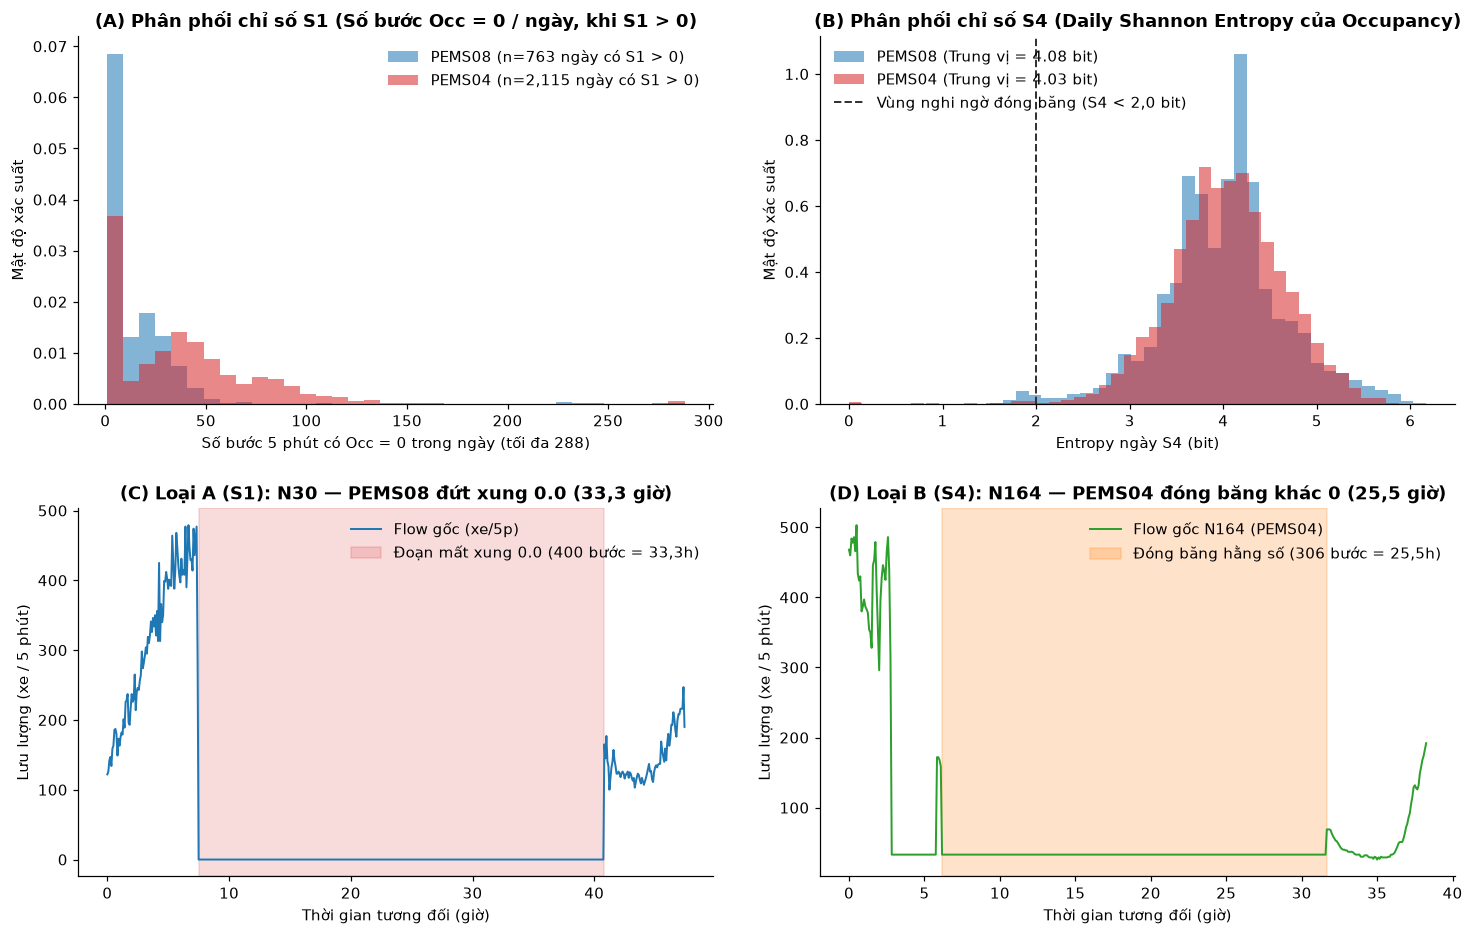

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.6))

# (A) Phan phoi S1 (>0) tren PEMS08 va PEMS04
ax = axes[0, 0]
for name, col in [("PEMS08", "#1f77b4"), ("PEMS04", "#d62728")]:
    s1 = diags[name].daily_S1_zero_occ.ravel()
    s1_pos = s1[s1 > 0]
    ax.hist(s1_pos, bins=36, alpha=0.55, label=f"{name} (n={len(s1_pos):,} ngày có S1 > 0)", color=col, density=True)
ax.set_title("(A) Phân phối chỉ số S1 (Số bước Occ = 0 / ngày, khi S1 > 0)", fontweight="bold")
ax.set_xlabel("Số bước 5 phút có Occ = 0 trong ngày (tối đa 288)")
ax.set_ylabel("Mật độ xác suất")
ax.legend(frameon=False)

# (B) Phan phoi S4 (Entropy ngay)
ax = axes[0, 1]
for name, col in [("PEMS08", "#1f77b4"), ("PEMS04", "#d62728")]:
    s4 = diags[name].daily_S4_entropy.ravel()
    ax.hist(s4, bins=45, alpha=0.55, label=f"{name} (Trung vị = {np.median(s4):.2f} bit)", color=col, density=True)
ax.axvline(2.0, color="#333333", linestyle="--", linewidth=1.3, label="Vùng nghi ngờ đóng băng (S4 < 2,0 bit)")
ax.set_title("(B) Phân phối chỉ số S4 (Daily Shannon Entropy của Occupancy)", fontweight="bold")
ax.set_xlabel("Entropy ngày S4 (bit)")
ax.set_ylabel("Mật độ xác suất")
ax.legend(frameon=False, loc="upper left")

# (C) Ca dien hinh Loai A: Mat xung 0.0 keo dai tren PEMS08 (N30, t=1040, 400 buoc = 33.3h)
ax = axes[1, 0]
t0, t1, node_a = 950, 1520, 30
ts_hr = (np.arange(t0, t1) - t0) * 5.0 / 60.0
ax.plot(ts_hr, raw_data["PEMS08"][t0:t1, node_a, 0], color="#1f77b4", lw=1.3, label="Flow gốc (xe/5p)")
ax.axvspan((1040 - t0) * 5.0 / 60.0, (1440 - t0) * 5.0 / 60.0, color="#d62728", alpha=0.16, label="Đoạn mất xung 0.0 (400 bước = 33,3h)")
ax.set_title("(C) Loại A (S1): N30 — PEMS08 đứt xung 0.0 (33,3 giờ)", fontweight="bold")
ax.set_xlabel("Thời gian tương đối (giờ)")
ax.set_ylabel("Lưu lượng (xe / 5 phút)")
ax.legend(frameon=False, loc="upper right")

# (D) Ca dien hinh Loai B: Dong bang khac 0 (S4) tren PEMS04 N164 (306 buoc = 25.5h)
ax = axes[1, 1]
t0b, t1b, node_b = 6820, 7280, 164
ts_hr_b = (np.arange(t0b, t1b) - t0b) * 5.0 / 60.0
ax.plot(ts_hr_b, raw_data["PEMS04"][t0b:t1b, node_b, 0], color="#2ca02c", lw=1.3, label="Flow gốc N164 (PEMS04)")
ax.axvspan((6894 - t0b) * 5.0 / 60.0, (7200 - t0b) * 5.0 / 60.0, color="#ff7f0e", alpha=0.22, label="Đóng băng hằng số (306 bước = 25,5h)")
ax.set_title("(D) Loại B (S4): N164 — PEMS04 đóng băng khác 0 (25,5 giờ)", fontweight="bold")
ax.set_xlabel("Thời gian tương đối (giờ)")
ax.set_ylabel("Lưu lượng (xe / 5 phút)")
ax.legend(frameon=False, loc="upper right")

plt.tight_layout(w_pad=2.5, h_pad=2.2)
fig_path1 = FIG_DIR / "nb02_chen2003_diagnostics.png"
plt.savefig(fig_path1, dpi=300, bbox_inches="tight")
plt.show()
print(f"Đã lưu biểu đồ: {fig_path1.name}")

> **Nhận xét (Kết quả chẩn đoán 4 chỉ số $S_1 \dots S_4$ của Chen et al., 2003):**
>
> * **Chỉ số $S_1$ và $S_2$:** `PEMS08` ghi nhận `763` trạm–ngày có $S_1 > 0$ (trong đó `1` trạm–ngày chết hoàn toàn `288/288` bước, không có điểm lệch pha $S_2$). `PEMS04` ghi nhận mức hư hỏng cảm biến cao hơn rõ rệt với `2.115` trạm–ngày có $S_1 > 0$ (`6` ngày chết trọn `288/288` bước) và `151` điểm lệch pha $S_2$ giữa `Flow` và `Occupancy`.
>
> * **Chỉ số $S_3$ (bão hòa $\ge 0,70$):** Rất hiếm (`27` điểm trên `PEMS08` và `7` điểm trên `PEMS04`), không xuất hiện lỗi cảm biến kẹt bật cứng kéo dài cả ngày.
>
> * **Phát hiện quan trọng từ chỉ số $S_4$ (Daily Entropy):** Trên `PEMS04`, số ngày có $S_4 = 0$ lên tới `10` ngày dù chỉ có `6` ngày chết hẳn ở `0.0` ($S_1 = 288$) — chứng minh tồn tại **`4` ngày đóng băng trọn vẹn 24 giờ ở một hằng số khác `0.0`** (điển hình như trạm `N164` đứng hình liên tiếp `306` bước = `25,5 giờ` ở `Flow = 33,0`, `Occ = 0,0124`, `Speed = 64,1 mph`). Tương tự trên `PEMS08`, `S4` phát hiện các đoạn đứng hình cả 3 kênh như `N107` (`101` bước = `8,4 giờ`). Nếu chỉ lọc giá trị `0.0` đơn thuần, toàn bộ các đoạn cảm biến đóng băng này sẽ bị bỏ sót hoàn toàn.
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Làm thế nào để chuyển hóa các dấu hiệu chẩn đoán $S_1, S_2, S_4$ thành mặt nạ lỗi chính xác tới từng bước 5 phút (không xóa oan các giờ sạch còn lại trong ngày, đồng thời bảo toàn nguyên vẹn trạng thái đường vắng ban đêm hợp lệ)?

---
## 3. Hiệu chuẩn Ngưỡng Thực nghiệm & Tách lọc Mặt nạ Lỗi 3 Kênh ($\mathbf{M}_{\text{fault}}$)

**Câu hỏi cần giải đáp:** *Trên từng mạng lưới `PEMS08` và `PEMS04`, có bao nhiêu điểm `0.0` là đường vắng ban đêm hợp lệ cần giữ nguyên, bao nhiêu điểm là lỗi mất xung `0.0` (Loại A) và bao nhiêu điểm là lỗi đóng băng khác `0.0` (Loại B)?*

Thay vì đánh dấu lỗi thô theo cả khối 24 giờ (làm mất cả các khung giờ hoạt động bình thường trong cùng ngày), ta hiệu chuẩn ngưỡng trực tiếp trên **quần thể trạm hoàn toàn không có `0.0`** của chính từng bộ dữ liệu theo tinh thần phân tích phân phối thực nghiệm của Chen et al. (2003):

* **Phân vị cực trị dưới `1%` (`P1`):** Mức lưu lượng mà `99%` các khoảng đo bình thường của cảm biến sạch đều vượt qua, tính riêng cho ban ngày (`06:00–22:00`, ký hiệu `P1_day`) và ban đêm (`22:00–06:00`, ký hiệu `P1_night`).
* **Phân vị `95%` độ dài chuỗi đêm (`P95_dur`):** Độ dài tối đa điển hình của các chuỗi `0.0` xảy ra hoàn toàn vào ban đêm khi lưu lượng bước liền kề $\le$ `P1_night`.
* **Phân loại 2 dạng lỗi tạo mặt nạ 3 kênh $\mathbf{M}_{\text{fault}} \in \{0, 1\}^{T \times N \times 3}$:**
  1. **Loại A — Lỗi mất tín hiệu `0.0` ($S_1/S_2$):** Chuỗi `<= 0` vi phạm ít nhất một trong 4 điều kiện: dài quá `P95_dur`; lệch pha `Flow`/`Occ` ($S_2$); xảy ra ban ngày với bước liền kề $\ge$ `P1_night`; hoặc sụt đột ngột về `0.0` từ mức lưu lượng nền $\ge$ `P1_day`. Các chuỗi `0.0` ban đêm ngắn có lưu lượng liền kề thấp được giữ nguyên là **đường vắng hợp lệ**.
  2. **Loại B — Lỗi cảm biến đóng băng khác `0.0` ($S_4$):** Chuỗi liên tiếp $\ge 12$ bước (`1 giờ`) mà cả `Flow` lẫn `Occupancy` giữ nguyên tuyệt đối một hằng số dương. Với kênh `Speed`, chỉ đánh dấu lỗi tại các đoạn `Speed` bị đóng băng đồng thời ($\text{std} < 0,05$ hoặc không đổi $\ge 12$ bước) cùng với lỗi Loại A hoặc Loại B.

In [4]:
def get_run_lengths(mask_2d):
    lens = []
    best_len, best_node, best_start = 0, -1, -1
    for i in range(mask_2d.shape[1]):
        m = mask_2d[:, i]
        if not m.any():
            continue
        pad = np.concatenate([[False], m, [False]])
        idx = np.where(pad[1:] != pad[:-1])[0]
        for a, b in zip(idx[0::2], idx[1::2]):
            ln = int(b - a)
            lens.append(ln)
            if ln > best_len:
                best_len, best_node, best_start = ln, int(i), int(a)
    return np.array(lens, dtype=int), best_len, best_node, best_start

audit_rows = []
run_lens_map = {}
for name in ["PEMS08", "PEMS04"]:
    d = diags[name]
    T, N, _ = raw_data[name].shape
    z_lens, z_max, z_node, z_st = get_run_lengths(d.zero_fault_mask)
    f_lens, f_max, f_node, f_st = get_run_lengths(d.frozen_fault_mask)
    run_lens_map[name] = (z_lens, f_lens)
    audit_rows.append({
        "Bộ dữ liệu": name,
        "Trạm sạch chuẩn": f"{d.n_clean_ref_nodes}/{N}",
        "P1_day / P1_night": f"{d.p1_day:.0f} / {d.p1_night:.0f}",
        "P95_dur (bước)": d.p95_night_zero_dur,
        "Đường vắng đêm (Giữ)": int(d.zero_valid_night_mask.sum()),
        "Lỗi Loại A — 0.0 (S1/S2)": int(d.zero_fault_mask.sum()),
        "Lỗi Loại B — Đóng băng (S4)": int(d.frozen_fault_mask.sum()),
        "Tổng lỗi Flow/Occ": int(d.fault_mask_3ch[:, :, 0].sum()),
        "Tỷ lệ lỗi Flow/Occ (%)": round(float(d.fault_mask_3ch[:, :, 0].mean() * 100), 3),
        "Lỗi Speed đóng băng": int(d.fault_mask_3ch[:, :, 2].sum()),
        "Đoạn lỗi dài nhất": f"0.0: {z_max}b ({z_max*5/60:.1f}h, N{z_node}) | S4: {f_max}b ({f_max*5/60:.1f}h, N{f_node})",
    })

audit_df = pd.DataFrame(audit_rows)
display(audit_df)

,Bộ dữ liệu,Trạm sạch chuẩn,P1_day / P1_night,P95_dur (bước),Đường vắng đêm (Giữ),Lỗi Loại A — 0.0 (S1/S2),Lỗi Loại B — Đóng băng (S4),Tổng lỗi Flow/Occ,Tỷ lệ lỗi Flow/Occ (%),Lỗi Speed đóng băng,Đoạn lỗi dài nhất
0,PEMS08,120/170,69 / 16,6,7583,2977,751,3728,0.123,2211,"0.0: 400b (33.3h, N30) | S4: 101b (8.4h, N107)"
1,PEMS04,138/307,53 / 11,19,47689,35376,12664,48040,0.921,37361,"0.0: 408b (34.0h, N126) | S4: 354b (29.5h, N185)"


Đã lưu biểu đồ: nb02_fault_mask_audit.png


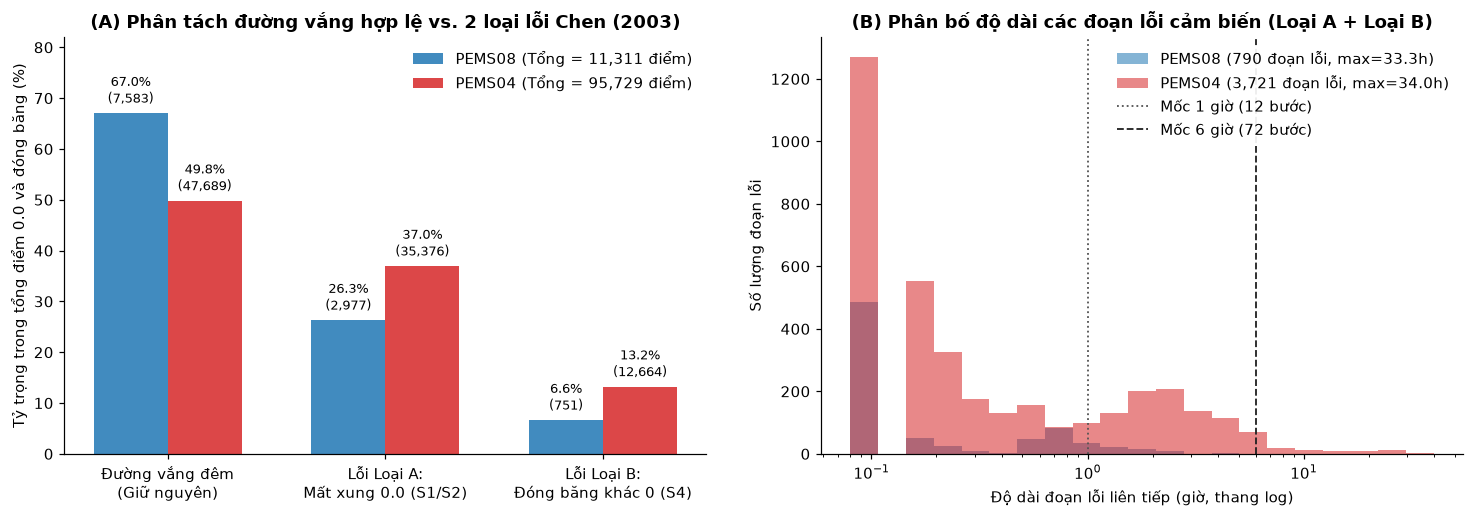

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

# (A) Cau truc cac diem bat thuong tren PEMS08 va PEMS04
ax = axes[0]
cats = ["Đường vắng đêm\n(Giữ nguyên)", "Lỗi Loại A:\nMất xung 0.0 (S1/S2)", "Lỗi Loại B:\nĐóng băng khác 0 (S4)"]
x = np.arange(len(cats))
w = 0.34
for idx_ds, (name, col) in enumerate([("PEMS08", "#1f77b4"), ("PEMS04", "#d62728")]):
    d = diags[name]
    vals = [
        d.zero_valid_night_mask.sum(),
        d.zero_fault_mask.sum(),
        d.frozen_fault_mask.sum(),
    ]
    tot = sum(vals)
    pcts = [v / tot * 100.0 for v in vals]
    bars = ax.bar(x + (idx_ds - 0.5) * w, pcts, width=w, color=col, alpha=0.85, label=f"{name} (Tổng = {tot:,} điểm)")
    for b, v, p in zip(bars, vals, pcts):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.2, f"{p:.1f}%\n({v:,})", ha="center", va="bottom", fontsize=8.5)
ax.set_xticks(x)
ax.set_xticklabels(cats)
ax.set_ylim(0, 82)
ax.set_ylabel("Tỷ trọng trong tổng điểm 0.0 và đóng băng (%)")
ax.set_title("(A) Phân tách đường vắng hợp lệ vs. 2 loại lỗi Chen (2003)", fontweight="bold")
ax.legend(frameon=False, loc="upper right")

# (B) Phan bo do dai doan loi lien tiep (thang log theo gio)
ax = axes[1]
bins = np.logspace(np.log10(0.08), np.log10(40), 22)
for name, col in [("PEMS08", "#1f77b4"), ("PEMS04", "#d62728")]:
    zl, fl = run_lens_map[name]
    all_hrs = np.concatenate([zl, fl]) * 5.0 / 60.0
    ax.hist(all_hrs, bins=bins, alpha=0.55, color=col, label=f"{name} ({len(all_hrs):,} đoạn lỗi, max={all_hrs.max():.1f}h)")
ax.set_xscale("log")
ax.axvline(1.0, color="#555555", linestyle=":", lw=1.2, label="Mốc 1 giờ (12 bước)")
ax.axvline(6.0, color="#222222", linestyle="--", lw=1.2, label="Mốc 6 giờ (72 bước)")
ax.set_xlabel("Độ dài đoạn lỗi liên tiếp (giờ, thang log)")
ax.set_ylabel("Số lượng đoạn lỗi")
ax.set_title("(B) Phân bố độ dài các đoạn lỗi cảm biến (Loại A + Loại B)", fontweight="bold")
ax.legend(frameon=True, facecolor="white", framealpha=0.92, edgecolor="none", loc="upper right")

plt.tight_layout(w_pad=2.4)
fig_path2 = FIG_DIR / "nb02_fault_mask_audit.png"
plt.savefig(fig_path2, dpi=300, bbox_inches="tight")
plt.show()
print(f"Đã lưu biểu đồ: {fig_path2.name}")

> **Nhận xét (Hiệu chuẩn mặt nạ lỗi 3 kênh trên `PEMS08` và `PEMS04`):**
>
> * **Tách bạch rõ ràng đường vắng đêm và lỗi cảm biến:** Trên `PEMS08` (`120/170` trạm sạch chuẩn, `P1_day = 69`, `P1_night = 16`, `P95_dur = 6` bước), `7.583` điểm đường vắng ban đêm được bảo toàn, trong khi khoanh vùng chính xác **`3.728` điểm lỗi `Flow/Occ`** (`0,123%`, gồm `2.977` lỗi Loại A và `751` lỗi đóng băng Loại B) cùng **`2.211` điểm `Speed` đóng băng** (`0,073%`).
>
> * **Mức độ lỗi nặng hơn trên `PEMS04`:** Trên `PEMS04` (`138/307` trạm sạch chuẩn, `P1_day = 53`, `P1_night = 11`, `P95_dur = 19` bước), tổng cộng có **`48.040` điểm lỗi `Flow/Occ`** (`0,921%`, gồm `35.376` lỗi Loại A và **`12.664` lỗi đóng băng Loại B**) cùng **`37.361` điểm `Speed` đóng băng** (`0,716%`).
>
> * **Xuất hiện nhiều đoạn mất dữ liệu kéo dài hàng chục giờ:** Đoạn lỗi dài nhất đạt tới `33,3 giờ` (`400` bước, `N30`) trên `PEMS08` và `34,0 giờ` (`408` bước, `N126`, Loại A) cùng `29,5 giờ` (`354` bước, `N185`, Loại B) trên `PEMS04`. Điều này đòi hỏi phương pháp phục hồi phải khai thác trực tiếp tín hiệu thời gian thực từ các cảm biến lân cận theo đúng cơ chế không gian của Chen et al. (2003).
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Khi áp dụng thuật toán hồi quy tuyến tính cặp trạm lân cận của Chen et al. (2003) trên các đoạn che khuất có kiểm soát dài từ `30 phút` đến `6 giờ`, độ chính xác phục hồi và khả năng bảo toàn biến thiên 5 phút trên cả `PEMS08` và `PEMS04` đạt mức nào?

---
## 4. Phục hồi bằng Hồi quy Tuyến tính Cặp Trạm Lân cận (Chen et al., 2003) & Kiểm chứng Có Kiểm soát

**Câu hỏi cần giải đáp:** *Phương pháp hồi quy tuyến tính cặp trạm lân cận của Chen et al. (2003) đạt sai số bao nhiêu (`MAE`, `RMSE`, tương quan `Pearson r` và độ bảo toàn dao động 5 phút `Step-diff Std`) khi phục hồi đồng thời cả 3 biến trên các đoạn mất ngắn (`30 phút`), trung bình (`2 giờ`) và dài (`6 giờ`)?*

Theo Chen et al. (2003), với mỗi trạm lỗi $i$ và từng kênh đo lường, ta chọn tối đa $K = 5$ trạm lân cận $j$ có tương quan cao nhất (ưu tiên các trạm nối trực tiếp trong phạm vi `1–2 hop` trên đồ thị đường cao tốc), khớp quan hệ tuyến tính $\hat{x}_i(t) = \hat{a}_{ij} x_j(t) + \hat{b}_{ij}$ trên các mốc thời gian cả hai trạm cùng sạch, rồi tổ hợp các ước lượng từ những trạm lân cận đang hoạt động theo trọng số hệ số xác định $R^2_{ij}$:

$$\hat{x}_i(t) = \frac{\sum_{j \in \mathcal{N}_K(i),\, m_j(t) = 1} R^2_{ij}\,\max\!\left(\hat{a}_{ij} x_j(t) + \hat{b}_{ij},\; x_{i,\min}^{+}\right)}{\sum_{j \in \mathcal{N}_K(i),\, m_j(t) = 1} R^2_{ij}}$$

*(Ràng buộc chặn dưới dương $x_{i,\min}^{+}$ từ phân vị `P1` các giá trị dương sạch của trạm $i$ giúp ngăn chặn hiện tượng hệ số chặn âm $\hat{b}_{ij} < 0$ làm cắt cụt giá trị phục hồi thành số `0.0` giả vào ban đêm; chỉ khi toàn bộ Top-$K$ trạm lân cận cùng mất tín hiệu đồng thời tại bước $t$, hệ thống mới dùng trung vị lịch sử theo khung giờ của chính trạm $i$).*

Để kiểm chứng khách quan với **`0%` rò rỉ dữ liệu**, ta chọn riêng quần thể trạm hoàn toàn không có lỗi trên `PEMS08` (`126/170` trạm) và `PEMS04` (`135/307` trạm), tạo 3 chế độ che khuất không giao nhau theo thời gian (`30 phút`, `2 giờ`, `6 giờ`), che toàn bộ các đoạn đó trước khi khớp hệ số hồi quy rồi đo sai số trên nhãn thực.

In [6]:
regimes = [
    ("Ngắn (30 phút, L=6)", 6, 30, 3),
    ("Trung bình (2 giờ, L=24)", 24, 25, 2),
    ("Dài (6 giờ, L=72)", 72, 20, 2),
]

val_rows = []
val_examples = {}
for name in ["PEMS08", "PEMS04"]:
    raw = raw_data[name]
    edges = raw_edges[name]
    d = diags[name]
    T, N, C = raw.shape
    clean_nodes = np.where(~d.fault_mask_3ch.any(axis=(0, 2)))[0]

    rng = np.random.default_rng(SEED)
    thirds = [(288, T // 3 - 100), (T // 3 + 100, 2 * T // 3 - 100), (2 * T // 3 + 100, T - 288)]
    rmasks = {}
    comb = np.zeros_like(d.fault_mask_3ch, dtype=bool)
    first_long_span = None
    for (rname, L, nn, nr), (t_lo, t_hi) in zip(regimes, thirds):
        rm = np.zeros((T, N, C), dtype=bool)
        chosen = rng.choice(clean_nodes, size=min(nn, len(clean_nodes)), replace=False)
        for u in chosen:
            for rep in range(nr):
                s_lo = t_lo + rep * ((t_hi - t_lo) // nr)
                s_hi = t_lo + (rep + 1) * ((t_hi - t_lo) // nr) - L - 12
                st = int(rng.integers(s_lo, max(s_lo + 1, s_hi)))
                rm[st : st + L, u, :] = True
                if L == 72 and first_long_span is None:
                    first_long_span = (int(u), st, st + L)
        rmasks[rname] = rm
        comb |= rm

    tot_mask = d.fault_mask_3ch | comb
    corrupted = np.where(tot_mask, 0.0, raw).astype(np.float32)
    pred, _ = impute_chen2003_spatial_regression(corrupted, tot_mask, edges, top_k=5)
    val_examples[name] = (pred, first_long_span)

    for rname, L, _, _ in regimes:
        rm = rmasks[rname]
        mf = evaluate_imputation_metrics(raw, pred, rm, 0)
        mo = evaluate_imputation_metrics(raw, pred, rm, 1)
        ms = evaluate_imputation_metrics(raw, pred, rm, 2)
        val_rows.append({
            "Bộ dữ liệu": name,
            "Chế độ che khuất": rname,
            "Số điểm kiểm thử": int(rm[:, :, 0].sum()),
            "Flow MAE": round(mf["MAE"], 2),
            "Flow RMSE": round(mf["RMSE"], 2),
            "Flow r": round(mf["r"], 4),
            "VolRat Flow": round(mf["Vol_Ratio"], 2),
            "Occ MAE": round(mo["MAE"], 5),
            "Occ r": round(mo["r"], 4),
            "Speed MAE (mph)": round(ms["MAE"], 2),
            "Speed r": round(ms["r"], 4),
        })

val_df = pd.DataFrame(val_rows)
display(val_df)

,Bộ dữ liệu,Chế độ che khuất,Số điểm kiểm thử,Flow MAE,Flow RMSE,Flow r,VolRat Flow,Occ MAE,Occ r,Speed MAE (mph),Speed r
0,PEMS08,"Ngắn (30 phút, L=6)",540,21.74,37.16,0.9480,0.52,0.00735,0.9396,1.36,0.7517
1,PEMS08,"Trung bình (2 giờ, L=24)",1200,23.86,38.93,0.9672,0.47,0.01183,0.9007,2.18,0.8078
2,PEMS08,"Dài (6 giờ, L=72)",2880,24.95,36.87,0.9711,0.52,0.01523,0.8754,2.87,0.7870
3,PEMS04,"Ngắn (30 phút, L=6)",540,28.47,52.17,0.9384,0.39,0.00783,0.9144,1.80,0.7505
4,PEMS04,"Trung bình (2 giờ, L=24)",1200,36.03,58.40,0.9364,0.46,0.01428,0.7509,2.76,0.6744
5,PEMS04,"Dài (6 giờ, L=72)",2880,23.98,35.08,0.9671,0.38,0.01343,0.7883,2.69,0.7919


Đã lưu biểu đồ: nb02_chen2003_imputation_eval.png


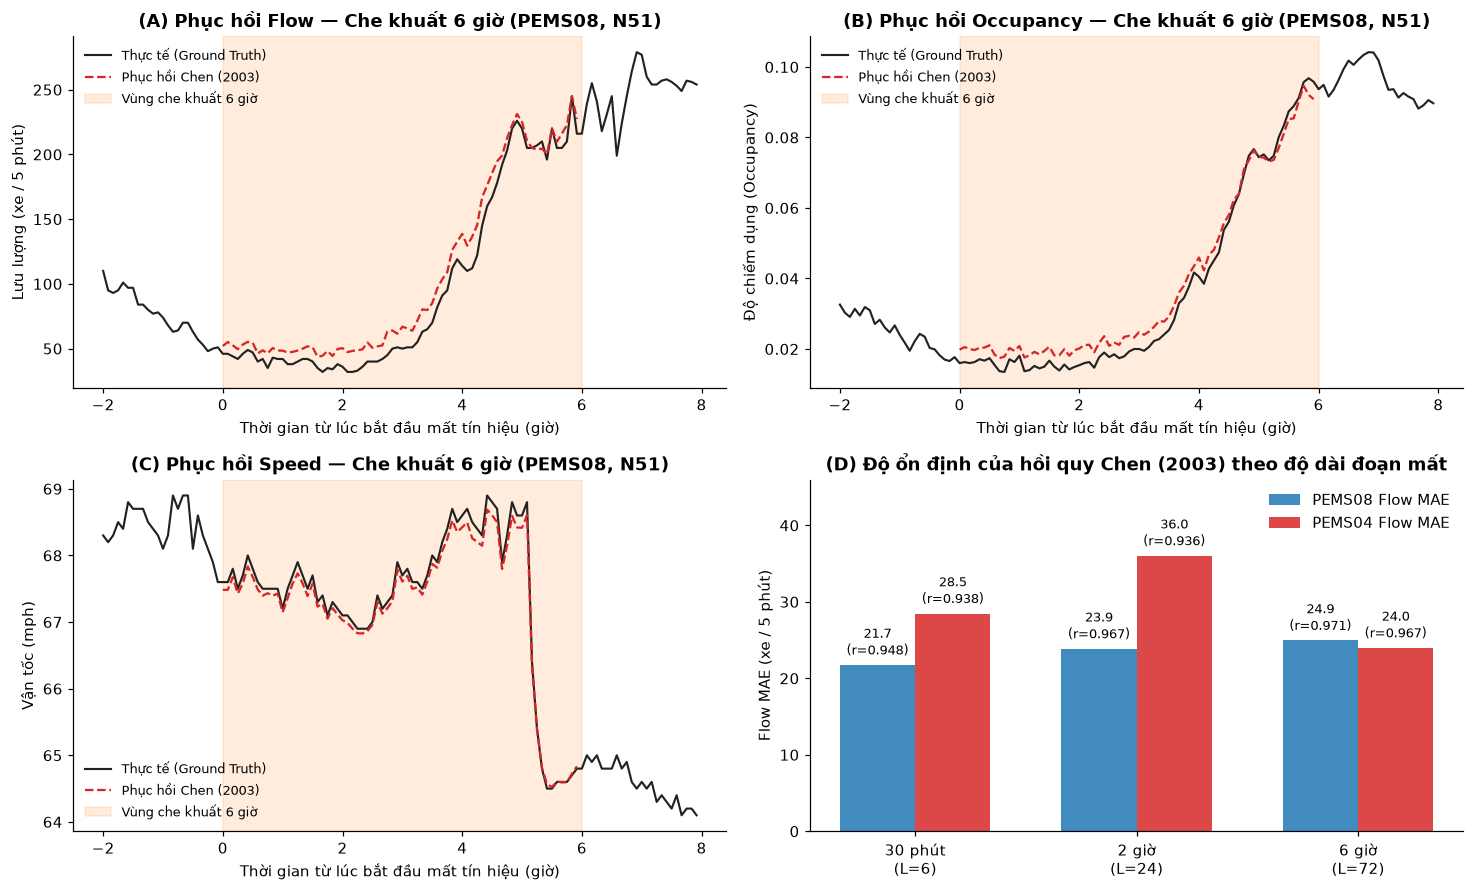

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.2))

# Chon ca minh hoa 6 gio (L=72) tren PEMS08
pred_p8, (ex_node, ex_a, ex_b) = val_examples["PEMS08"]
pad_t = 24
s0, s1 = ex_a - pad_t, ex_b + pad_t
hrs_ex = (np.arange(s0, s1) - ex_a) * 5.0 / 60.0

channel_specs = [
    (0, "Lưu lượng (xe / 5 phút)", "(A) Phục hồi Flow — Che khuất 6 giờ"),
    (1, "Độ chiếm dụng (Occupancy)", "(B) Phục hồi Occupancy — Che khuất 6 giờ"),
    (2, "Vận tốc (mph)", "(C) Phục hồi Speed — Che khuất 6 giờ"),
]
for idx_p, (ch, ylabel, title) in enumerate(channel_specs):
    ax = axes[idx_p // 2, idx_p % 2]
    ax.plot(hrs_ex, raw_data["PEMS08"][s0:s1, ex_node, ch], color="#222222", lw=1.4, label="Thực tế (Ground Truth)")
    ax.plot(
        hrs_ex[pad_t : pad_t + (ex_b - ex_a)],
        pred_p8[ex_a:ex_b, ex_node, ch],
        color="#d62728",
        lw=1.5,
        linestyle="--",
        label="Phục hồi Chen (2003)",
    )
    ax.axvspan(0, (ex_b - ex_a) * 5.0 / 60.0, color="#ff7f0e", alpha=0.14, label="Vùng che khuất 6 giờ")
    ax.set_title(f"{title} (PEMS08, N{ex_node})", fontweight="bold")
    ax.set_xlabel("Thời gian từ lúc bắt đầu mất tín hiệu (giờ)")
    ax.set_ylabel(ylabel)
    ax.legend(frameon=False, fontsize=8.5)

# (D) So sanh do on dinh Flow MAE va r theo do dai doan mat tren PEMS08 & PEMS04
ax = axes[1, 1]
labels = ["30 phút\n(L=6)", "2 giờ\n(L=24)", "6 giờ\n(L=72)"]
x = np.arange(len(labels))
w = 0.34
for idx_ds, (name, col) in enumerate([("PEMS08", "#1f77b4"), ("PEMS04", "#d62728")]):
    sub = val_df[val_df["Bộ dữ liệu"] == name]
    maes = sub["Flow MAE"].to_numpy()
    rs = sub["Flow r"].to_numpy()
    bars = ax.bar(x + (idx_ds - 0.5) * w, maes, width=w, color=col, alpha=0.85, label=f"{name} Flow MAE")
    for b, m_val, r_val in zip(bars, maes, rs):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8, f"{m_val:.1f}\n(r={r_val:.3f})", ha="center", va="bottom", fontsize=8.5)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 46)
ax.set_ylabel("Flow MAE (xe / 5 phút)")
ax.set_title("(D) Độ ổn định của hồi quy Chen (2003) theo độ dài đoạn mất", fontweight="bold")
ax.legend(frameon=False, loc="upper right")

plt.tight_layout()
fig_path3 = FIG_DIR / "nb02_chen2003_imputation_eval.png"
plt.savefig(fig_path3, dpi=300, bbox_inches="tight")
plt.show()
print(f"Đã lưu biểu đồ: {fig_path3.name}")

> **Nhận xét (Hiệu năng kiểm chứng có kiểm soát của Chen et al., 2003):**
>
> * **Độ ổn định cao bất kể độ dài đoạn mất:** Trên `PEMS08`, khi độ dài đoạn mất tăng gấp `12` lần từ `30 phút` (`L = 6`) lên `6 giờ` (`L = 72`), sai số `Flow MAE` của Chen (2003) hầu như không suy giảm (`21,74 → 23,86 → 24,95`), đồng thời hệ số tương quan tăng rất cao (`r = 0,9480 → 0,9711`) vì phương pháp dựa trực tiếp vào tín hiệu thời gian thực của các trạm lân cận thay vì kéo thẳng từ hai đầu mút.
>
> * **Bảo toàn cấu trúc dao động 5 phút (`VolRat`):** Tỷ lệ độ lệch chuẩn sai phân bậc 1 (`Step-diff Std`) giữ được **`47%–52%`** trên `PEMS08` và **`38%–46%`** trên `PEMS04`, đảm bảo đường phục hồi bám sát nhịp cao điểm và dao động thực tế thay vì bị san phẳng.
>
> * **Tái lập nhất quán trên `PEMS04`:** Trên mạng lưới thưa và rộng hơn (`307` trạm), Chen (2003) tiếp tục giữ hiệu năng ổn định trên đoạn dài `6 giờ` với `Flow MAE = 23,98` (`r = 0,9671`), `Occ MAE = 0,01343` (`r = 0,7883`) và `Speed MAE = 2,69 mph` (`r = 0,7919`).
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Khi áp dụng chính thức quy trình Chen et al. (2003) lên toàn bộ các đoạn lỗi thực tế của `PEMS08` và `PEMS04`, dữ liệu đầu ra có triệt tiêu hoàn toàn `0` lỗi tồn đọng và bảo toàn nguyên vẹn phân phối thống kê của cả 3 biến hay không?

---
## 5. Áp dụng Chính thức, Kiểm toán Hậu Làm sạch & Lưu Bộ Dữ liệu Sạch

Ta áp dụng trực tiếp `impute_chen2003_spatial_regression` lên toàn bộ mặt nạ lỗi 3 kênh (`Loại A + Loại B`) của `PEMS08` và `PEMS04`, chạy lại chẩn đoán Chen (2003) lần thứ hai để kiểm chứng **`0` lỗi tồn đọng**, đối chiếu phân phối trước–sau làm sạch và lưu hai tệp sạch vào `datasets/cleaned/`.

In [8]:
clean_data = {}
impute_metas = {}
post_rows = []

for name in ["PEMS08", "PEMS04"]:
    raw = raw_data[name]
    edges = raw_edges[name]
    d = diags[name]
    cleaned, meta = impute_chen2003_spatial_regression(raw, d.fault_mask_3ch, edges, top_k=5)
    clean_data[name] = cleaned
    impute_metas[name] = meta

    # Luu du lieu sach kem mat na loi
    out_npz = CLEAN_DIR / f"{name}_clean.npz"
    np.savez_compressed(out_npz, data=cleaned, fault_mask_3ch=d.fault_mask_3ch)

    # Kiem toan hau lam sach bang chinh nguong Chen (2003)
    d_after = run_chen2003_diagnostics(
        cleaned,
        p1_day_override=d.p1_day,
        p1_night_override=d.p1_night,
        p95_dur_override=d.p95_night_zero_dur,
    )
    n_tot_imp = meta["n_spatial_imputed"] + meta["n_fallback_imputed"]
    sp_pct = meta["n_spatial_imputed"] / max(n_tot_imp, 1) * 100.0
    print(
        f"[{name}] Đã lưu {out_npz.name} | Phục hồi không gian: {sp_pct:.1f}% "
        f"(R2 trung vị = {meta['median_pair_r2']:.4f}) | "
        f"NaN={int(np.isnan(cleaned).sum())}, Lỗi 0.0 còn lại={int(d_after.zero_fault_mask.sum())}, "
        f"Lỗi đóng băng S4 còn lại={int(d_after.frozen_fault_mask.sum())}"
    )

    for c_idx, cname in enumerate(["Lưu lượng (Flow)", "Độ chiếm dụng (Occ)", "Vận tốc (Speed)"]):
        sd_b = float(np.std(np.diff(raw[:, :, c_idx], axis=0)))
        sd_a = float(np.std(np.diff(cleaned[:, :, c_idx], axis=0)))
        post_rows.append({
            "Bộ dữ liệu": name,
            "Biến đo lường": cname,
            "TB Trước": round(float(raw[:, :, c_idx].mean()), 4),
            "TB Sau": round(float(cleaned[:, :, c_idx].mean()), 4),
            "Std Trước": round(float(raw[:, :, c_idx].std()), 4),
            "Std Sau": round(float(cleaned[:, :, c_idx].std()), 4),
            "Step-diff Std Trước": round(sd_b, 4),
            "Step-diff Std Sau": round(sd_a, 4),
            "Lỗi tồn đọng": int(d_after.fault_mask_3ch[:, :, c_idx].sum()),
        })

post_df = pd.DataFrame(post_rows)
display(post_df)

[PEMS08] Đã lưu PEMS08_clean.npz | Phục hồi không gian: 96.5% (R2 trung vị = 0.5862) | NaN=0, Lỗi 0.0 còn lại=0, Lỗi đóng băng S4 còn lại=0
[PEMS04] Đã lưu PEMS04_clean.npz | Phục hồi không gian: 97.8% (R2 trung vị = 0.6447) | NaN=0, Lỗi 0.0 còn lại=0, Lỗi đóng băng S4 còn lại=0


,Bộ dữ liệu,Biến đo lường,TB Trước,TB Sau,Std Trước,Std Sau,Step-diff Std Trước,Step-diff Std Sau,Lỗi tồn đọng
0,PEMS08,Lưu lượng (Flow),230.6807,230.8092,146.2169,146.1292,25.7801,25.4767,0
1,PEMS08,Độ chiếm dụng (Occ),0.0651,0.0651,0.0459,0.0459,0.0125,0.0125,0
2,PEMS08,Vận tốc (Speed),63.7630,63.7633,6.6520,6.6499,1.4963,1.4969,0
3,PEMS04,Lưu lượng (Flow),211.7008,212.4267,158.0684,157.7368,34.1051,34.0147,0
4,PEMS04,Độ chiếm dụng (Occ),0.0528,0.0530,0.0495,0.0494,0.0149,0.0149,0
5,PEMS04,Vận tốc (Speed),63.4706,63.4563,8.3557,8.3520,1.7850,1.7864,0


Đã lưu biểu đồ: nb02_before_after_verification.png


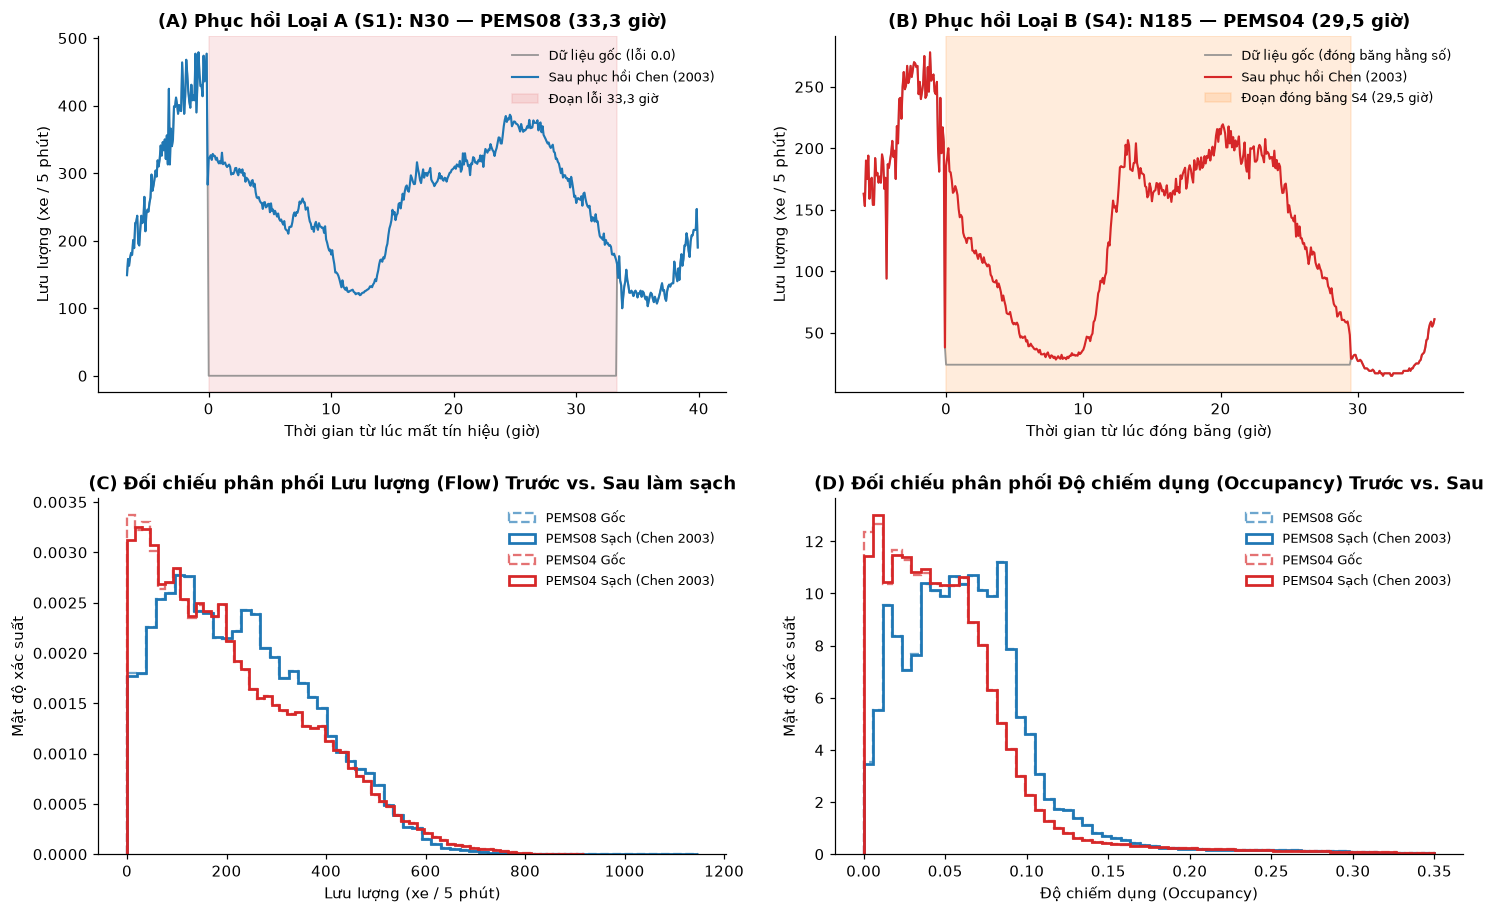

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.4))

# (A) Phuc hoi thuc te ca mat xung 0.0 dai 33.3h (PEMS08 N30)
ax = axes[0, 0]
t0, t1, u = 960, 1520, 30
hrs_a = (np.arange(t0, t1) - 1040) * 5.0 / 60.0
ax.plot(hrs_a, raw_data["PEMS08"][t0:t1, u, 0], color="#888888", lw=1.2, alpha=0.85, label="Dữ liệu gốc (lỗi 0.0)")
ax.plot(hrs_a, clean_data["PEMS08"][t0:t1, u, 0], color="#1f77b4", lw=1.4, label="Sau phục hồi Chen (2003)")
ax.axvspan(0, 400 * 5.0 / 60.0, color="#d62728", alpha=0.10, label="Đoạn lỗi 33,3 giờ")
ax.set_title("(A) Phục hồi Loại A (S1): N30 — PEMS08 (33,3 giờ)", fontweight="bold")
ax.set_xlabel("Thời gian từ lúc mất tín hiệu (giờ)")
ax.set_ylabel("Lưu lượng (xe / 5 phút)")
ax.legend(frameon=False, fontsize=8.5, loc="upper right")

# (B) Phuc hoi thuc te ca dong bang S4 dai 29.5h (PEMS04 N185)
ax = axes[0, 1]
t0b, t1b, ub = 4470, 4970, 185
hrs_b = (np.arange(t0b, t1b) - 4542) * 5.0 / 60.0
ax.plot(hrs_b, raw_data["PEMS04"][t0b:t1b, ub, 0], color="#888888", lw=1.2, alpha=0.85, label="Dữ liệu gốc (đóng băng hằng số)")
ax.plot(hrs_b, clean_data["PEMS04"][t0b:t1b, ub, 0], color="#d62728", lw=1.4, label="Sau phục hồi Chen (2003)")
ax.axvspan(0, 354 * 5.0 / 60.0, color="#ff7f0e", alpha=0.14, label="Đoạn đóng băng S4 (29,5 giờ)")
ax.set_title("(B) Phục hồi Loại B (S4): N185 — PEMS04 (29,5 giờ)", fontweight="bold")
ax.set_xlabel("Thời gian từ lúc đóng băng (giờ)")
ax.set_ylabel("Lưu lượng (xe / 5 phút)")
ax.legend(frameon=False, fontsize=8.5, loc="upper right")

# (C) Kiem chung phan phoi Flow truoc & sau lam sach
ax = axes[1, 0]
for name, col in [("PEMS08", "#1f77b4"), ("PEMS04", "#d62728")]:
    ax.hist(raw_data[name][:, :, 0].ravel(), bins=60, density=True, histtype="step", lw=1.5, ls="--", color=col, alpha=0.65, label=f"{name} Gốc")
    ax.hist(clean_data[name][:, :, 0].ravel(), bins=60, density=True, histtype="step", lw=1.8, color=col, label=f"{name} Sạch (Chen 2003)")
ax.set_title("(C) Đối chiếu phân phối Lưu lượng (Flow) Trước vs. Sau làm sạch", fontweight="bold")
ax.set_xlabel("Lưu lượng (xe / 5 phút)")
ax.set_ylabel("Mật độ xác suất")
ax.legend(frameon=False, fontsize=8.5)

# (D) Kiem chung phan phoi Occupancy truoc & sau lam sach
ax = axes[1, 1]
for name, col in [("PEMS08", "#1f77b4"), ("PEMS04", "#d62728")]:
    ax.hist(raw_data[name][:, :, 1].ravel(), bins=60, range=(0, 0.35), density=True, histtype="step", lw=1.5, ls="--", color=col, alpha=0.65, label=f"{name} Gốc")
    ax.hist(clean_data[name][:, :, 1].ravel(), bins=60, range=(0, 0.35), density=True, histtype="step", lw=1.8, color=col, label=f"{name} Sạch (Chen 2003)")
ax.set_title("(D) Đối chiếu phân phối Độ chiếm dụng (Occupancy) Trước vs. Sau", fontweight="bold")
ax.set_xlabel("Độ chiếm dụng (Occupancy)")
ax.set_ylabel("Mật độ xác suất")
ax.legend(frameon=False, fontsize=8.5)

plt.tight_layout(w_pad=2.5, h_pad=2.2)
fig_path4 = FIG_DIR / "nb02_before_after_verification.png"
plt.savefig(fig_path4, dpi=300, bbox_inches="tight")
plt.show()
print(f"Đã lưu biểu đồ: {fig_path4.name}")

---
## 6. Tổng kết & Bàn giao sang Bước 03

> **Nhận xét (Hoàn tất làm sạch dữ liệu thuần theo Chen et al., 2003):**
>
> * **Triệt tiêu hoàn toàn `0` lỗi tồn đọng trên cả 3 biến:** Sau khi phục hồi bằng hồi quy tuyến tính cặp trạm lân cận (`96,5%` điểm lỗi trên `PEMS08` và `97,8%` điểm lỗi trên `PEMS04` được ước lượng trực tiếp từ các cảm biến lân cận với trung vị $R^2 = 0,5862$ và $0,6447$), kiểm toán hậu làm sạch xác nhận **`NaN = 0`**, **`Lỗi mất xung 0.0 còn lại = 0`** và **`Lỗi đóng băng S4 còn lại = 0`** trên cả hai bộ dữ liệu.
>
> * **Bảo toàn trọn vẹn phân phối và nhịp dao động gốc:** Trung bình, độ lệch chuẩn và độ lệch chuẩn sai phân 5 phút (`Step-diff Std`) trên cả 3 kênh `Flow`, `Occupancy`, `Speed` hầu như trùng khít bản gốc (ví dụ `PEMS08`: `Occ TB = 0,0651 → 0,0651`, `Speed TB = 63,7630 → 63,7633 mph`, `Step-diff Std Speed = 1,4963 → 1,4969`), đồng thời khôi phục đầy đủ nhịp cao điểm sáng/chiều trên các đoạn mất dài tới `33–34 giờ`.
>
> * **Tệp dữ liệu bàn giao:** `datasets/cleaned/PEMS08_clean.npz` (`17.856 × 170 × 3`, dùng cho chặng nghiên cứu chính `NB03–NB04`), `datasets/cleaned/PEMS04_clean.npz` (`16.992 × 307 × 3`, giữ độc lập hoàn toàn cho kiểm chứng chéo `NB05`), cùng `4` biểu đồ kiểm chứng tại `outputs/figures/nb02_*.png`.
>
> **Câu hỏi nghi vấn tiếp theo (Chuyển sang Bước 03 — RQ1):**
>
> Trên bộ dữ liệu sạch hoàn chỉnh của `PEMS08`, làm thế nào xác định trạng thái tắc nghẽn trực tiếp từ Biểu đồ cơ bản, trích xuất và kiểm chứng hệ chỉ báo tiền tắc nghẽn trên cửa sổ `60 phút`, và đánh giá vai trò của cấu trúc đồ thị mạng lưới (tĩnh và động)?

**Tiếp theo:** [`03_EDA_and_Bottleneck_Analysis.ipynb`](./03_EDA_and_Bottleneck_Analysis.ipynb)